# H15 Part A · Step 2 · The side-car and its loss

The review of **step 2** of [the plan](../../../docs/drivejepa-perception-sidecar-A.md) (§4–5). It opens the
model (`gallops.drivejepa_perception.sidecar`) part by part and builds its loss by hand, then checks every
number against the code that trains:

1. the model, part by part, and the three variants;
2. where the queries start;
3. Hungarian matching, worked on a toy example;
4. each term of the loss on the toy, checked against `SideCarLoss`;
5. the loss on a real batch, before any training;
6. a short fit: does every term go down?

**Kernel:** `drive-jepa-v2` ("Drive-JEPA v2") at this site: it starts the interpreter `gallops.toml` names as `[python] drivejepa` (Python 3.9, torch 2.1), the one these outputs came from. Not `python3` ("Python 3 (ipykernel)"), which starts the system Python without torch, and not `drive-jepa-py39`, another venv with another navsim tree first on its path. Elsewhere, any kernel that starts `[python] drivejepa`. Headless: `scripts/run_notebooks.py`. It runs on the CPU and reads only the caches.

In [1]:
import json
import os
import sys
import warnings
from pathlib import Path

REPO = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "src" / "gallops").is_dir())
sys.path.insert(0, str(REPO / "src"))
os.environ.setdefault("GALLOPS_CONFIG", str(REPO / "gallops.toml"))
warnings.filterwarnings("ignore")

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
from matplotlib.patches import Polygon
from matplotlib.ticker import FuncFormatter
from scipy.optimize import linear_sum_assignment

from gallops.config import SiteConfig
from gallops.drivejepa_perception import navsim_data, sidecar, train_sidecar, views
from gallops.drivejepa_perception import targets as tg

views.use_style()
pd.set_option("display.precision", 3)
torch.set_num_threads(16)
cfg = SiteConfig.load()
RUNS = Path(cfg.resolve("{runs}")) / "drivejepa_perception"
labels = dict(np.load(RUNS / "labels-v1" / "labels.npz"))
logs = json.loads((RUNS / "labels-v1" / "manifest.json").read_text())["logs"]
token_logs = np.array([logs[i] for i in labels["log_id"]])
splits = json.loads((REPO / "recipes" / "drivejepa_perception" / "splits.json").read_text())
rows = {s: np.flatnonzero(np.isin(token_logs, splits[s])) for s in ("train", "select", "report")}
proj = tg.front_projection(np.asarray(np.load(RUNS / "tokens-v1" / "lidar2img.npy", mmap_mode="r"))).astype(np.float32)
vit = np.load(RUNS / "tokens-vit-v1" / "vit_out.npy", mmap_mode="r")  # (103,288, 512, 1024) fp16
print("ViT-out cache:", vit.shape, vit.dtype)


def targets_of(row):
    return tg.build(navsim_data.agents_of(labels, row), proj[row])


def batch_of(picked):
    """The trainer's batch for these rows (train_sidecar.Rows, collated), on the CPU in fp32."""
    items = [train_sidecar.Rows(vit, int, picked, proj, {r: targets_of(r) for r in picked})[i] for i in range(len(picked))]
    batch = torch.utils.data.default_collate(items)
    batch["tokens"] = batch["tokens"].float()
    return batch


def y_axis_left(ax):
    ax.xaxis.set_major_formatter(FuncFormatter(lambda v, _: f"{-v:g}"))
    ax.set_xlabel("y (m): + left, − right")
    ax.set_ylabel("x (m), forward")

ViT-out cache: (103288, 512, 1024) float16


## 1. The model, part by part

The side-car reads two things per sample: the ViT's output, **512 tokens × 1024**, and CAM_F0's 4×4
projection (ego → the 512×256 token image). Everything below is v1, the first pass's A1 side-car, built
exactly as the trainer builds it (`train_sidecar.build_model`, seed 0).

In [2]:
torch.manual_seed(0)
v1 = train_sidecar.build_model({"tap": "vit_out", **train_sidecar.VARIANTS["v1"]})


def count(module):
    return sum(p.numel() for p in module.parameters())


layer = v1.layers[0]
parts = {
    "input projection: Linear 1024 → 256 + LayerNorm": count(v1.proj) + count(v1.ln_tok),
    "token rays: MLP 48 → 256 → 256": count(v1.ray_mlp),
    "query position: MLP 3 → 256 → 256": count(v1.pos_mlp),
    "64 queries (256) + 64 reference points (3)": v1.query.numel() + v1.ref.numel(),
    "per layer · self-attention (q, k, v, out)": count(layer.sa),
    "per layer · cross-attention (q, k, v, out)": count(layer.ca),
    "per layer · FFN 256 → 1024 → 256": count(layer.ffn),
    "per layer · 3 LayerNorms": count(layer.ln_sa) + count(layer.ln_ca) + count(layer.ln_ff),
    "per layer · heads (class 4, Δcentre 3, box 5, velocity 2, path 4)": count(layer.cls_head)
    + count(layer.ref_mlp) + count(layer.box_head) + count(layer.vel_head) + count(layer.path_head),
}
table = pd.Series(parts, name="parameters").to_frame()
table["per model (3 layers)"] = [v if not k.startswith("per layer") else 3 * v for k, v in parts.items()]
print(f"v1: {count(v1):,} parameters")
table

v1: 4,388,342 parameters


,parameters,per model (3 layers)
input projection: Linear 1024 → 256 + LayerNorm,262912,262912
token rays: MLP 48 → 256 → 256,78336,78336
query position: MLP 3 → 256 → 256,66816,66816
64 queries (256) + 64 reference points (3),16576,16576
"per layer · self-attention (q, k, v, out)",263168,789504
"per layer · cross-attention (q, k, v, out)",263168,789504
per layer · FFN 256 → 1024 → 256,525568,1576704
per layer · 3 LayerNorms,1536,4608
"per layer · heads (class 4, Δcentre 3, box 5, velocity 2, path 4)",267794,803382


In [3]:
INFERENCE_PATH = 307_860_553  # the released model's inference path (H15 plan, §2)
rows_v = []
for name, arch in train_sidecar.VARIANTS.items():
    model = train_sidecar.build_model({"tap": "vit_out", **arch})
    rows_v.append({"variant": name, **arch, "parameters (M)": count(model) / 1e6,
                   "share of the inference path": count(model) / INFERENCE_PATH})
pd.DataFrame(rows_v).set_index("variant")

,d_model,heads,ffn,layers,queries,parameters (M),share of the inference path
variant,,,,,,,
v1,256,8,1024,3,64,4.388,0.014
v2,256,8,1024,6,128,8.369,0.027
v3,384,12,1536,6,128,18.444,0.060


**What comes out.** One dictionary per decoder layer; every layer is supervised, only the last is read.
A forward of four real train samples:

In [4]:
picked = np.random.default_rng(0).choice(rows["train"], 4, replace=False)
batch4 = batch_of(picked)
v1.eval()
with torch.no_grad():
    outs = v1(batch4["tokens"], batch4["projection"])
pd.DataFrame(
    {k: [tuple(o[k].shape) for o in outs] for k in ("logits", "box", "vel", "path")},
    index=[f"layer {i}" for i in range(len(outs))],
)

,logits,box,vel,path
layer 0,"(4, 64, 4)","(4, 64, 8)","(4, 64, 2)","(4, 64, 2, 2)"
layer 1,"(4, 64, 4)","(4, 64, 8)","(4, 64, 2)","(4, 64, 2, 2)"
layer 2,"(4, 64, 4)","(4, 64, 8)","(4, 64, 2)","(4, 64, 2, 2)"


- `logits` (B, 64, 4): vehicle, pedestrian, cyclist, none.
- `box` (B, 64, 8): centre x, y, z (m, ego frame) = reference point + Δcentre; then log l, log w, log h,
  sin yaw, cos yaw.
- `vel` (B, 64, 2): vx, vy (m/s, the ego's axes; ground velocity).
- `path` (B, 64, 2, 2): offsets from the slot's own centre at +0.5 s and +1.0 s.

## 2. Where the queries start

Each of the 64 queries has a learned **reference point**, its first guess of where its agent is. They start
uniform over x 2–50 m, |y| < 30 m, z 0 (`SideCar.__init__`, seeded by the run's seed). Below: v1's start at
seed 0 against the camera's view and against where train targets actually are. A point outside the view
can still find an agent (its first layer's Δcentre is unbounded), but it starts with no prior.

v1: 32 of 64 reference points start inside the camera's view (50%)
v2: 65 of 128 reference points start inside the camera's view (51%)


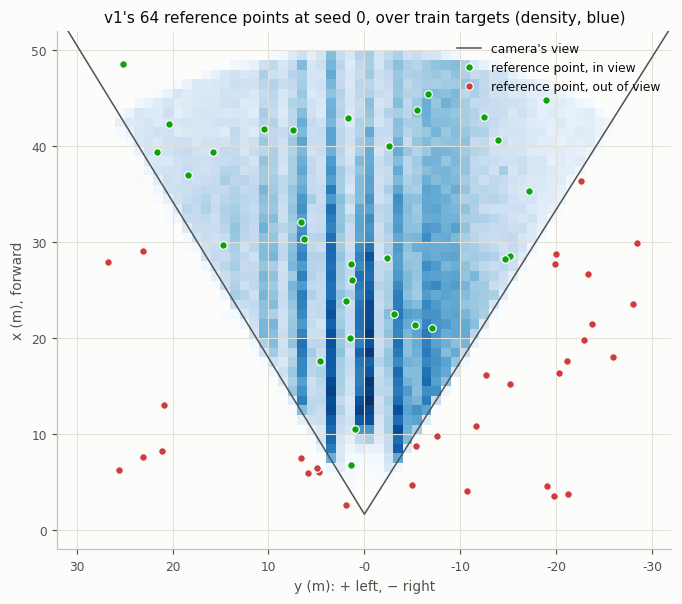

In [5]:
row0 = int(rows["select"][0])
for name in ("v1", "v2"):
    torch.manual_seed(0)
    model = train_sidecar.build_model({"tap": "vit_out", **train_sidecar.VARIANTS[name]})
    ref = model.ref.detach().numpy().astype(np.float64)
    inside = tg.seen(proj[row0].astype(np.float64), ref)
    print(f"{name}: {int(inside.sum())} of {len(ref)} reference points start inside the camera's view "
          f"({inside.mean():.0%})")

torch.manual_seed(0)
ref = v1.ref.detach().numpy()
sample = np.random.default_rng(1).choice(rows["train"], 20000, replace=False)
xy = np.concatenate([(lambda t: t["box"][t["mask"], :2])(targets_of(r)) for r in sample])
fig, ax = plt.subplots(figsize=(7.2, 6.2))
ax.hist2d(-xy[:, 1], xy[:, 0], bins=[np.linspace(-32, 32, 65), np.linspace(-2, 52, 55)], cmap="Blues", cmin=1)
edges = views.view_edges(proj[row0], reach=60)
ax.plot(-edges[[1, 0, 2], 1], edges[[1, 0, 2], 0], color=views.INK_2, lw=1.0, label="camera's view")
inside = tg.seen(proj[row0].astype(np.float64), ref.astype(np.float64))
ax.plot(-ref[inside, 1], ref[inside, 0], "o", ms=5, color=views.HIT, mec=views.SURFACE, mew=0.8, label="reference point, in view")
ax.plot(-ref[~inside, 1], ref[~inside, 0], "o", ms=5, color=views.MISS, mec=views.SURFACE, mew=0.8, label="reference point, out of view")
ax.set_xlim(-32, 32)
ax.set_ylim(-2, 52)
ax.set_aspect("equal")
y_axis_left(ax)
ax.legend(loc="upper right")
ax.set_title("v1's 64 reference points at seed 0, over train targets (density, blue)")
plt.show()

## 3. Hungarian matching, by hand

Before any loss, each sample's targets are paired one-to-one with slots (DETR's set matching), separately
for every decoder layer. The cost of giving slot *q* to target *g*:

$$C_{qg} = 2 \cdot \big(-p_q(\text{class of } g)\big) + 0.25 \cdot \lVert c_q - c_g \rVert_1$$

with $p_q$ the slot's softmax over the four classes and $c$ the 3D centre in metres. `scipy`'s
`linear_sum_assignment` finds the pairing with the least total cost; every target gets a slot, the other
slots become "none".

**The toy:** two targets (a vehicle 12 m ahead, a pedestrian 8 m ahead and 3 m to the right) and five
slots. Slot 0 sits on the vehicle but thinks "pedestrian"; slot 1 is 2 m off but sure of "vehicle".

In [6]:
NONE = tg.NONE
toy_logits = torch.tensor([[[0.0, 2.5, 0.0, 1.0],   # slot 0: on the vehicle, says pedestrian
                            [3.0, 0.0, 0.0, 0.5],   # slot 1: 2 m off the vehicle, says vehicle
                            [0.0, 2.0, 0.0, 0.5],   # slot 2: near the pedestrian, says pedestrian
                            [0.0, 0.0, 0.0, 3.0],   # slot 3: far away, says none
                            [1.0, 1.0, 0.0, 1.0]]])  # slot 4: undecided, 20 m away
toy_centres = torch.tensor([[[12.0, 0.0, 0.8], [14.0, 0.0, 0.8], [8.5, -3.0, 0.9], [40.0, 10.0, 0.0], [30.0, 0.0, 0.0]]])
toy_box = torch.zeros(1, 5, 8)
toy_box[..., :3] = toy_centres
toy_out = {"logits": toy_logits, "box": toy_box, "vel": torch.zeros(1, 5, 2), "path": torch.zeros(1, 5, 2, 2)}

toy_t = {k: torch.from_numpy(v)[None] for k, v in tg.build(
    {
        "cls": np.array([0, 1], np.int8),
        "box": np.array([[12.0, 0.0, 0.8, 4.5, 1.9, 1.6, 0.1], [8.0, -3.0, 0.9, 0.7, 0.7, 1.8, 1.6]], np.float32),
        "velocity": np.array([[5.0, 0.2], [0.0, 1.2]], np.float32),
        "path": np.array([[[14.5, 0.3], [17.0, 0.4]], [[8.0, -2.4], [np.nan, np.nan]]], np.float32),
        "path_ok": np.array([[True, True], [True, False]]),
    },
    np.diag([1.0, 1.0, 1.0, 1.0]) @ np.array([[256, -400, 0, 0], [128, 0, -400, 600], [1, 0, 0, 0], [0, 0, 0, 1.0]]),
).items()}
print("targets (nearest first):", [views.CLASS_NAMES[c] for c in toy_t["cls"][0][toy_t["mask"][0]].tolist()])

p = toy_logits.softmax(-1)[0]
cls_t = toy_t["cls"][0][toy_t["mask"][0]]
ctr_t = toy_t["box"][0][toy_t["mask"][0], :3]
class_cost = -2.0 * p[:, cls_t]
centre_cost = 0.25 * torch.cdist(toy_centres[0], ctr_t, p=1)
total = class_cost + centre_cost
names = [f"target {j}: {views.CLASS_NAMES[c]}" for j, c in enumerate(cls_t.tolist())]
cost_table = pd.concat(
    {"−2 · p(class)": pd.DataFrame(class_cost.numpy(), columns=names),
     "0.25 · L1 centre": pd.DataFrame(centre_cost.numpy(), columns=names),
     "total": pd.DataFrame(total.numpy(), columns=names)}, axis=1)
cost_table.index = [f"slot {q}" for q in range(5)]
cost_table

targets (nearest first): ['pedestrian', 'vehicle']


−2 · p(class)                       0.25 · L1 centre  \
       target 0: pedestrian target 1: vehicle target 0: pedestrian   
slot 0               -1.442            -0.118                1.775   
slot 1               -0.084            -1.693                2.275   
slot 2               -1.339            -0.181                0.125   
slot 3               -0.087            -0.087               11.475   
slot 4               -0.594            -0.594                6.475   

                                        total                    
       target 1: vehicle target 0: pedestrian target 1: vehicle  
slot 0              0.00                0.333            -0.118  
slot 1              0.50                2.191            -1.193  
slot 2              1.65               -1.214             1.469  
slot 3              9.70               11.388             9.613  
slot 4              4.70                5.881             4.106

In [7]:
q_idx, g_idx = linear_sum_assignment(total.numpy())
print("by hand:     slot -> target", dict(zip(q_idx.tolist(), g_idx.tolist())))
(i, j), = [m for m in sidecar.hungarian(toy_out, toy_t["cls"], toy_t["box"], toy_t["mask"])]
print("sidecar.hungarian:", dict(zip(i.tolist(), j.tolist())))
assert dict(zip(q_idx.tolist(), g_idx.tolist())) == dict(zip(i.tolist(), j.tolist()))

by hand:     slot -> target {1: 1, 2: 0}
sidecar.hungarian: {1: 1, 2: 0}


The vehicle goes to **slot 1**, 2 m off but confident (−1.69 for its class, +0.50 for 2 m: −1.19), not to
slot 0, which sits on it but votes "pedestrian" (−0.12 + 0.00). The pedestrian goes to slot 2. The class term is worth up to 2 and the centre term 0.25 per metre,
so **8 m of distance trades against full certainty**: early in training, when every slot says "none",
matching is almost purely by distance to the reference points; later, class confidence takes over.

## 4. Each term of the loss, on the toy

**Class: softmax focal loss.** For a slot whose target class has probability $p_t$:
$\;\text{FL} = -(1-p_t)^\gamma \log p_t$, with γ = 2 and no class weights. A matched slot's target is its
agent's class; every other slot's target is "none". The term is **summed over all slots of the batch and
divided by the number of targets**. γ down-weights the easy cases, mostly the many "none" slots that are
already right:

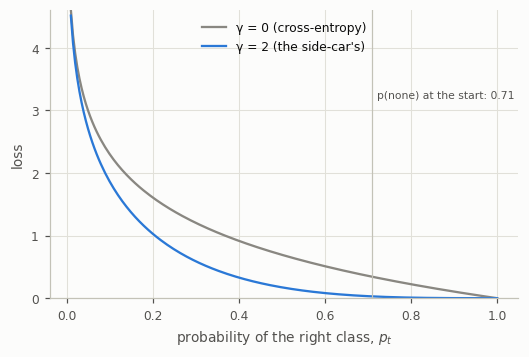

In [8]:
pt = np.linspace(0.01, 1.0, 200)
fig, ax = plt.subplots(figsize=(5.5, 3.4))
for gamma, colour in ((0, views.GREY), (2, views.CLASS_COLOURS[0])):
    ax.plot(pt, -((1 - pt) ** gamma) * np.log(pt), color=colour, label=f"γ = {gamma}" + (" (cross-entropy)" if gamma == 0 else " (the side-car's)"))
ax.axvline(0.71, color=views.AXIS, lw=0.8)
ax.text(0.72, 3.2, "p(none) at the start: 0.71", fontsize=7, color=views.INK_2)
ax.set_xlabel("probability of the right class, $p_t$")
ax.set_ylabel("loss")
ax.set_ylim(0, 4.6)
ax.legend()
plt.show()

In [9]:
idx = sidecar.hungarian(toy_out, toy_t["cls"], toy_t["box"], toy_t["mask"])
slots, tgts = idx[0]
target_cls = torch.full((1, 5), NONE)
target_cls[0, torch.as_tensor(slots)] = toy_t["cls"][0, torch.as_tensor(tgts)]
focal = sidecar.softmax_focal(toy_logits, target_cls)[0]
n = toy_t["mask"].sum().float()
print("each slot's class target:", [("none" if c == NONE else views.CLASS_NAMES[c]) for c in target_cls[0].tolist()])
print("focal per slot:", np.round(focal.numpy(), 3).tolist())
l_cls = focal.sum() / n
print(f"class term = sum / {int(n)} targets = {float(l_cls):.4f}")

each slot's class target: ['none', 'vehicle', 'pedestrian', 'none', 'none']
focal per slot: [1.2869999408721924, 0.004000000189989805, 0.04399999976158142, 0.0020000000949949026, 0.6000000238418579]
class term = sum / 2 targets = 0.9686


**Box.** Each matched slot against its target in 8 numbers: the centre in metres, the size as logs (a 10%
size error costs the same for a bus as for a pedestrian), and the yaw as sin and cos (no jump at ±180°).
L1, summed over the 8, divided by the number of targets. The transform (`sidecar.box_targets`):

In [10]:
box8 = sidecar.box_targets(toy_t["box"])
pd.DataFrame(box8[0, :2].numpy(), columns=["x", "y", "z", "log l", "log w", "log h", "sin yaw", "cos yaw"],
             index=names)

,x,y,z,log l,log w,log h,sin yaw,cos yaw
target 0: pedestrian,8.0,-3.0,0.9,-0.357,-0.357,0.588,1.0,-0.029
target 1: vehicle,12.0,0.0,0.8,1.504,0.642,0.470,0.1,0.995


In [11]:
toy_out["box"][0, 1, 3:] = torch.tensor([1.4, 0.6, 0.5, 0.0, 1.0])  # slot 1's size and yaw
toy_out["vel"][0, 1] = torch.tensor([4.0, 0.0])
toy_out["path"][0, 1] = torch.tensor([[2.0, 0.0], [4.0, 0.0]])
toy_out["path"][0, 2] = torch.tensor([[0.0, 0.5], [0.0, 1.0]])
pi, ti = torch.as_tensor(slots), torch.as_tensor(tgts)
l_box = (toy_out["box"][0, pi] - box8[0, ti]).abs().sum() / n
l_vel = (toy_out["vel"][0, pi] - toy_t["vel"][0, ti]).abs().sum() / n
ok = toy_t["path_ok"][0, ti][..., None].float()
n_path = toy_t["path_ok"].sum().clamp(min=1).float()
l_path = ((toy_out["path"][0, pi] - toy_t["path"][0, ti]).abs() * ok).sum() / n_path
by_hand = 2 * l_cls + 0.25 * l_box + 0.25 * l_vel + 0.25 * l_path
loss, parts = sidecar.SideCarLoss()([toy_out], toy_t)
pd.DataFrame(
    {"by hand": [float(l_cls), float(l_box), float(l_vel), float(l_path), float(by_hand)],
     "SideCarLoss": [parts["cls0"], parts["box0"], parts["vel0"], parts["path0"], float(loss)],
     "weight": [2, 0.25, 0.25, 0.25, ""]},
    index=["class (focal, / targets)", "box (L1 of 8, / targets)", "velocity (L1, / targets)",
           f"path (L1 where the track lasted, / {int(n_path)} valid steps)", "total"],
)

,by hand,SideCarLoss,weight
"class (focal, / targets)",0.969,0.969,2
"box (L1 of 8, / targets)",2.555,2.555,0.25
"velocity (L1, / targets)",1.200,1.200,0.25
"path (L1 where the track lasted, / 3 valid steps)",0.767,0.767,0.25
total,3.068,3.068,


In [12]:
assert abs(float(loss) - float(by_hand)) < 1e-5
print("the loss built by hand equals SideCarLoss's on the toy")

the loss built by hand equals SideCarLoss's on the toy


**Two details the toy shows.**
- The pedestrian's +1.0 s step is unknown (its track ended), so that step adds nothing and is not counted
  in the path term's denominator: **the path term divides by valid steps (3 here), the others by
  targets (2)**. Per target, the path term weighs about half of what its 0.25 suggests.
- The box term mixes units: three centre numbers in metres, five unitless. Once sizes and yaw are learnt,
  it is mostly a centre-distance loss.

The whole loss is the sum of this over the **three** layers, each matched on its own.

## 5. The loss on a real batch, before any training

Sixteen train samples (seeded), v1 at seed 0, exactly as step 0 of a run sees them (fp32 here; the run uses
fp16 autocast for the forward).

In [13]:
picked = np.random.default_rng(5).choice(rows["train"], 16, replace=False)
batch = batch_of(picked)
torch.manual_seed(0)
model = train_sidecar.build_model({"tap": "vit_out", **train_sidecar.VARIANTS["v1"]})
model.train()
torch.manual_seed(0)
outs = model(batch["tokens"], batch["projection"])
loss, parts = sidecar.SideCarLoss()(outs, batch)
print(f"{int(batch['mask'].sum())} targets in 16 samples; total loss {float(loss):.2f}")
weights = {"cls": 2, "box": 0.25, "vel": 0.25, "path": 0.25}
start = pd.DataFrame({f"layer {l}": {term: parts[f"{term}{l}"] for term in weights} for l in range(3)})
start["weight"] = pd.Series(weights)
start.loc["weighted sum"] = [sum(weights[t] * parts[f"{t}{l}"] for t in weights) for l in range(3)] + [""]
start

99 targets in 16 samples; total loss 25.61


,layer 0,layer 1,layer 2,weight
cls,2.187,2.367,2.417,2.0
box,11.444,11.544,11.311,0.25
vel,2.197,2.299,2.222,0.25
path,1.826,1.932,1.888,0.25
weighted sum,8.240,8.678,8.690,


**Reading it.** At the start every slot says "none" with p ≈ 0.71, so the class term is mostly the targets'
slots, each costing −(1 − 0.097)² log 0.097 ≈ 1.9, plus 0.03 for each of the other slots, divided by the
targets: 1.9 × 99 + 0.03 × 925, over 99 targets, is 2.2, as measured for layer 0. The box term is several
metres of centre error per target: each target is matched to the nearest reference point, and the
references are spread over 2,880 m². Every layer starts at the same centres (Δcentre is zero-initialised),
so the three layers' box terms are almost equal at step 0; their class terms differ because each layer's
class head starts from its own random weights.

Which of the box term's 8 numbers carry it:

In [14]:
idx = sidecar.hungarian(outs[-1], batch["cls"], batch["box"], batch["mask"])
bi = torch.cat([torch.full((len(i),), b) for b, (i, _) in enumerate(idx)])
pi = torch.cat([torch.as_tensor(i) for i, _ in idx])
ti = torch.cat([torch.as_tensor(j) for _, j in idx])
err = (outs[-1]["box"][bi, pi] - sidecar.box_targets(batch["box"])[bi, ti]).abs().detach().numpy()
pd.Series(err.mean(0), index=["x", "y", "z", "log l", "log w", "log h", "sin yaw", "cos yaw"], name="mean |error| per target, last layer").to_frame().T

,x,y,z,log l,log w,log h,sin yaw,cos yaw
"mean |error| per target, last layer",2.789,4.879,0.732,0.758,0.468,0.474,0.401,0.809


**The matching at step 0, for one sample:** each target (class colour) joined to the slot it was matched
to, at that slot's centre (its reference point).

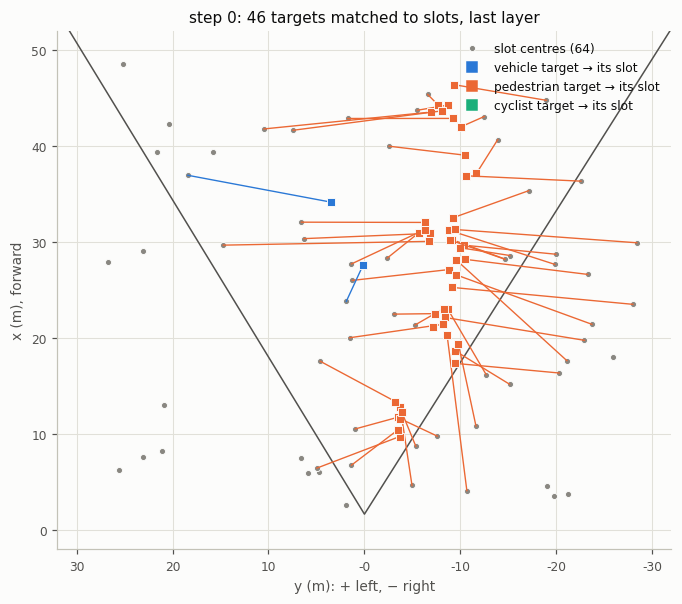

In [15]:
b = int(np.argmax([len(j) for _, j in idx]))
i_b, j_b = idx[b]
t_b = {k: v[b].numpy() for k, v in batch.items() if k not in ("tokens", "projection")}
centres = outs[-1]["box"][b, :, :2].detach().numpy()
fig, ax = plt.subplots(figsize=(7.2, 6.2))
edges = views.view_edges(batch["projection"][b].numpy(), reach=60)
ax.plot(-edges[[1, 0, 2], 1], edges[[1, 0, 2], 0], color=views.INK_2, lw=1.0)
ax.plot(-centres[:, 1], centres[:, 0], "o", ms=4, color=views.GREY, mec=views.SURFACE, mew=0.6, label="slot centres (64)")
for q, g in zip(i_b, j_b):
    colour = views.CLASS_COLOURS[t_b["cls"][g]]
    ax.plot([-centres[q, 1], -t_b["box"][g, 1]], [centres[q, 0], t_b["box"][g, 0]], color=colour, lw=0.9)
    ax.plot(-t_b["box"][g, 1], t_b["box"][g, 0], "s", ms=5, color=colour, mec=views.SURFACE, mew=0.6)
for c, name in enumerate(views.CLASS_NAMES):
    ax.plot([], [], "s", color=views.CLASS_COLOURS[c], label=f"{name} target → its slot")
ax.set_aspect("equal")
y_axis_left(ax)
ax.set_xlim(-32, 32)
ax.set_ylim(-2, 52)
ax.legend(loc="upper right")
ax.set_title(f"step 0: {len(j_b)} targets matched to slots, last layer")
plt.show()

## 6. A short fit: does every term go down?

The same 16 samples, the run's optimiser (AdamW 2e-4, weight decay 0.01, clip 35), 300 steps on the CPU in
fp32. An illustration, not the check: the check is the trainer's own `overfit` (64 samples, until the
matched centre error is under 0.5 m and class accuracy over 95%), whose log follows.

In [16]:
torch.manual_seed(0)
model = train_sidecar.build_model({"tap": "vit_out", **train_sidecar.VARIANTS["v1"]})
optimiser = torch.optim.AdamW(model.parameters(), lr=train_sidecar.LR, weight_decay=train_sidecar.WEIGHT_DECAY)
criterion = sidecar.SideCarLoss()
history = []
model.train()
for step in range(1, 301):
    outs = model(batch["tokens"], batch["projection"])
    loss, parts = criterion(outs, batch)
    optimiser.zero_grad(set_to_none=True)
    loss.backward()
    grad_norm = float(torch.nn.utils.clip_grad_norm_(model.parameters(), train_sidecar.CLIP))
    optimiser.step()
    numbers = train_sidecar.match_numbers(outs[-1], batch, parts["_match"])
    history.append({"step": step, "loss": float(loss), "grad_norm": grad_norm, **numbers,
                    **{k: v for k, v in parts.items() if not k.startswith("_")}})
history = pd.DataFrame(history)
print(history.iloc[[0, 49, 99, 199, 299]][["step", "loss", "cls2", "box2", "vel2", "path2", "match_centre_m", "match_class_acc"]].round(3).to_string(index=False))

 step   loss  cls2   box2  vel2  path2  match_centre_m  match_class_acc
    1 25.606 2.429 11.318 2.191  1.890           6.434            0.000
   50 10.653 0.357  8.219 1.632  1.444           5.683            0.626
  100  6.245 0.043  6.259 0.858  0.763           4.420            0.949
  200  3.098 0.007  3.001 0.549  0.482           1.845            1.000
  300  1.790 0.001  1.738 0.366  0.328           0.937            1.000


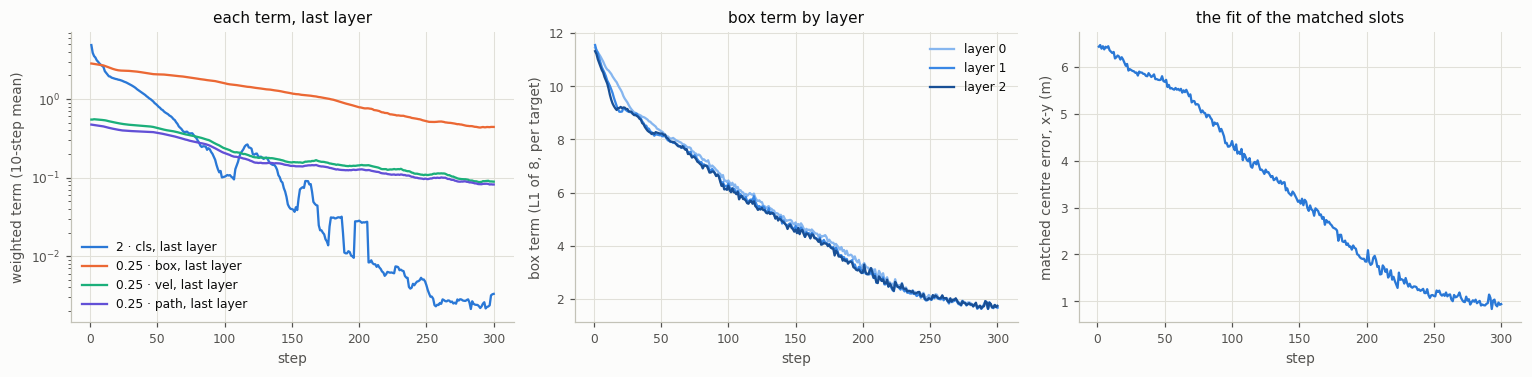

In [17]:
fig, axes = plt.subplots(1, 3, figsize=(14, 3.5))
ax = axes[0]
for term, colour in zip(("cls", "box", "vel", "path"), ("#2a78d6", "#eb6834", "#1baf7a", "#6250d6")):
    smooth = (history[f"{term}2"] * weights[term]).rolling(10, min_periods=1).mean()
    ax.plot(history.step, smooth, color=colour, label=f"{weights[term]} · {term}, last layer")
ax.set_yscale("log")
ax.set_xlabel("step")
ax.set_ylabel("weighted term (10-step mean)")
ax.legend()
ax.set_title("each term, last layer")
ax = axes[1]
for l, colour in zip(range(3), ("#86b6ef", "#3987e5", "#184f95")):
    ax.plot(history.step, history[f"box{l}"], color=colour, label=f"layer {l}")
ax.set_xlabel("step")
ax.set_ylabel("box term (L1 of 8, per target)")
ax.legend()
ax.set_title("box term by layer")
ax = axes[2]
ax.plot(history.step, history.match_centre_m, color=views.CLASS_COLOURS[0])
ax.set_xlabel("step")
ax.set_ylabel("matched centre error, x-y (m)")
ax.set_title("the fit of the matched slots")
plt.tight_layout()
plt.show()

**The trainer's own overfit check** (`part-a-overfit`, recipe stage of step 3; on the GPU, 64 train samples,
constant learning rate): its log, as written.

['overfit check passed at step 1300']


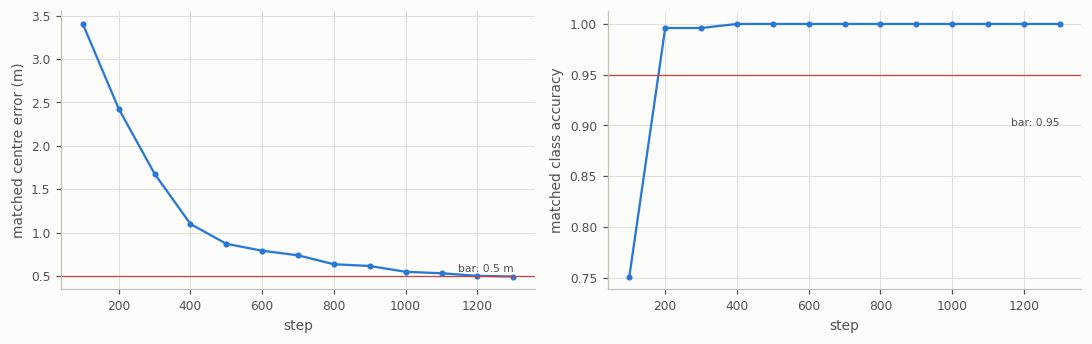

In [18]:
import re

log_lines = (RUNS / "part-a" / "r1-overfit.log").read_text().splitlines()
steps = [tuple(map(float, m.groups())) for m in (re.match(r"step (\d+): loss ([\d.]+) centre ([\d.]+) m class acc ([\d.]+)", l) for l in log_lines) if m]
overfit = pd.DataFrame(steps, columns=["step", "loss", "centre (m)", "class accuracy"])
print([l for l in log_lines if "overfit check" in l])
fig, axes = plt.subplots(1, 2, figsize=(10, 3.2))
axes[0].plot(overfit.step, overfit["centre (m)"], "o-", ms=3, color=views.CLASS_COLOURS[0])
axes[0].axhline(0.5, color=views.MISS, lw=0.8)
axes[0].text(overfit.step.max(), 0.55, "bar: 0.5 m", ha="right", fontsize=7, color=views.INK_2)
axes[0].set_xlabel("step")
axes[0].set_ylabel("matched centre error (m)")
axes[1].plot(overfit.step, overfit["class accuracy"], "o-", ms=3, color=views.CLASS_COLOURS[0])
axes[1].axhline(0.95, color=views.MISS, lw=0.8)
axes[1].text(overfit.step.max(), 0.9, "bar: 0.95", ha="right", fontsize=7, color=views.INK_2)
axes[1].set_xlabel("step")
axes[1].set_ylabel("matched class accuracy")
plt.tight_layout()
plt.show()

## Summary for the review

1. **The loss is what the plan says it is**: the matching and every term, built by hand, equal
   `SideCarLoss` to 1e-5 on the toy.
2. **Matching trades 8 m of distance against full class certainty.** At the start, when every slot says
   "none", matching is by distance to the reference points.
3. **About half of the reference points start outside the camera's view** (counted above for v1 and v2).
   They are not stuck (the first layer's Δcentre is unbounded), but they start with no prior; v1 keeps
   this to stay comparable with the first pass.
4. **The box term is mostly centre distance in metres**, and the path term divides by valid steps, not
   targets: two weightings the plan records rather than changes (§5).
5. **Every term falls on a fixed batch.** The class term goes first (class accuracy 1.00 by step 200),
   the box term follows. The later layers sit only slightly below the first in so short a fit; whether
   they earn their keep on real data is read from the runs' per-layer curves (notebook 03). The trainer's
   own overfit check passed at step 1,300 of 4,000 (centre 0.49 m, class accuracy 1.00).